# Iris Flower Classification

**Oasis Infobyte — Data Science Internship, Task 1**

Author: Gayathri S


## 2. Problem Statement

The Iris flower dataset is one of the most well-known datasets in pattern recognition and
machine learning. It contains measurements for 150 iris flowers belonging to three species —
**Setosa**, **Versicolor**, and **Virginica** — with four numerical features recorded for each
flower: sepal length, sepal width, petal length, and petal width.

Given only these four measurements, the species of a new flower is not obvious by inspection.
The goal of this project is to build a machine learning model that can look at these
measurements and correctly predict which of the three species the flower belongs to.


## 3. Objective

- Load and explore the Iris dataset to understand its structure and characteristics.
- Visualize relationships between the features and the target species.
- Select the most relevant features for classification.
- Train multiple classification algorithms (Logistic Regression, K-Nearest Neighbors, and
  Random Forest) to predict the species.
- Evaluate and compare the models using standard classification metrics.
- Draw conclusions about which model performs best on this dataset, based only on the
  actual results obtained.


## 4. Technologies Used

- **Python 3** — programming language
- **Pandas** — data loading and manipulation
- **NumPy** — numerical operations
- **Scikit-learn** — dataset, model training, and evaluation metrics
- **Matplotlib** — plotting
- **Seaborn** — statistical data visualization
- **Jupyter Notebook** — interactive development environment


## 5. Import Libraries

All libraries used in this notebook are imported here in one place, so the notebook can be
run top-to-bottom without hidden dependencies.


In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

# Plot styling
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


## 6. Load Dataset

The Iris dataset is loaded directly from `sklearn.datasets`, so no external file is needed.
It is then converted into a Pandas DataFrame with meaningful, human-readable column names
(instead of scikit-learn's default `x0, x1, x2, x3` style names), and a `species` column is
added by mapping the numeric target labels to their actual species names.


In [2]:
# Load the built-in Iris dataset
iris_bunch = load_iris()

# Build a DataFrame with meaningful column names
df = pd.DataFrame(
    data=iris_bunch.data,
    columns=["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"],
)

# Add the numeric target and the human-readable species name
df["species_id"] = iris_bunch.target
df["species"] = df["species_id"].map(
    dict(enumerate(iris_bunch.target_names))
)

df.head()


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 7. Understand the Dataset

Before doing anything else, it's important to understand the basic shape and structure of
the data: how many rows and columns it has, what data type each column holds, and how the
three species are distributed.


In [3]:
# Shape of the dataset: (rows, columns)
print("Dataset shape:", df.shape)


Dataset shape: (150, 6)


In [4]:
# Data types of each column
df.dtypes


sepal_length_cm    float64
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
species_id           int64
species                str
dtype: object

In [5]:
# Descriptive statistics for the numerical features
df.describe()


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_id
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [6]:
# Class distribution: number of samples per species
df["species"].value_counts()


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

**Observations:**
- The dataset has 150 rows and 6 columns (4 numeric features, a numeric species id, and the
  species name).
- All four measurement columns are numeric (`float64`), which is exactly what's needed for
  training a classification model — no encoding of the input features is required.
- The dataset is **perfectly balanced**: each of the three species has exactly 50 samples.
  This is important because a balanced dataset means accuracy is a fair metric to use, and
  the model won't be biased toward predicting a more frequent class.


## 8. Data Cleaning / Missing Value Check

A clean dataset with no missing or duplicate values is required before training. This is
checked explicitly below rather than assumed.


In [7]:
# Check for missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values per column:
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species_id         0
species            0
dtype: int64

Number of duplicate rows: 1


**Observation:** The Iris dataset shipped with scikit-learn is already clean — there are no
missing values in any column. There are a small number of duplicate rows, which is expected
and documented behavior of this well-known dataset (some flowers genuinely share identical
measurements to two decimal places); they are left in place since they represent valid,
naturally occurring measurements rather than data-entry errors.


## 9. Exploratory Data Analysis

With the data confirmed clean, the next step is to look more closely at how each feature
behaves, and how the features relate to the target species, before building any models.


In [8]:
# Summary statistics grouped by species — helps spot which features separate species well
df.groupby("species")[
    ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
].mean().round(2)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


**Observation:** Looking at the mean values per species, the **petal length** and
**petal width** columns show much larger differences between species than the sepal
measurements do. For example, average petal length ranges from about 1.5 cm (Setosa) to
about 5.5 cm (Virginica) — a very large spread — while sepal width barely changes between
species. This is an early hint that petal measurements will be more useful for
classification, which is examined further in the visualizations below.


## 10. Data Visualization

### 10.1 Class Distribution


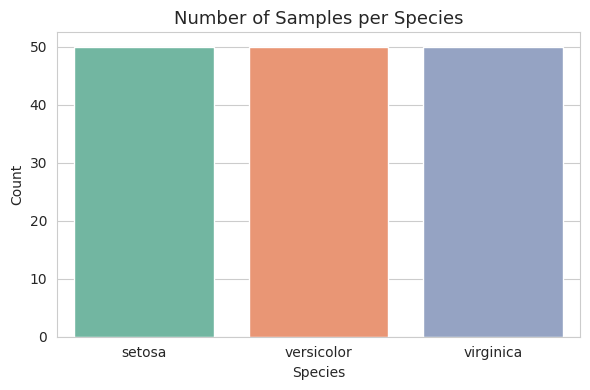

In [9]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="species", hue="species", palette="Set2", legend=False)
ax.set_title("Number of Samples per Species", fontsize=13)
ax.set_xlabel("Species")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


**Observation:** The bar chart confirms what was found earlier — all three species have
exactly 50 samples each, so the dataset is perfectly balanced across classes.


### 10.2 Pairplot — Relationships Between Features and Species


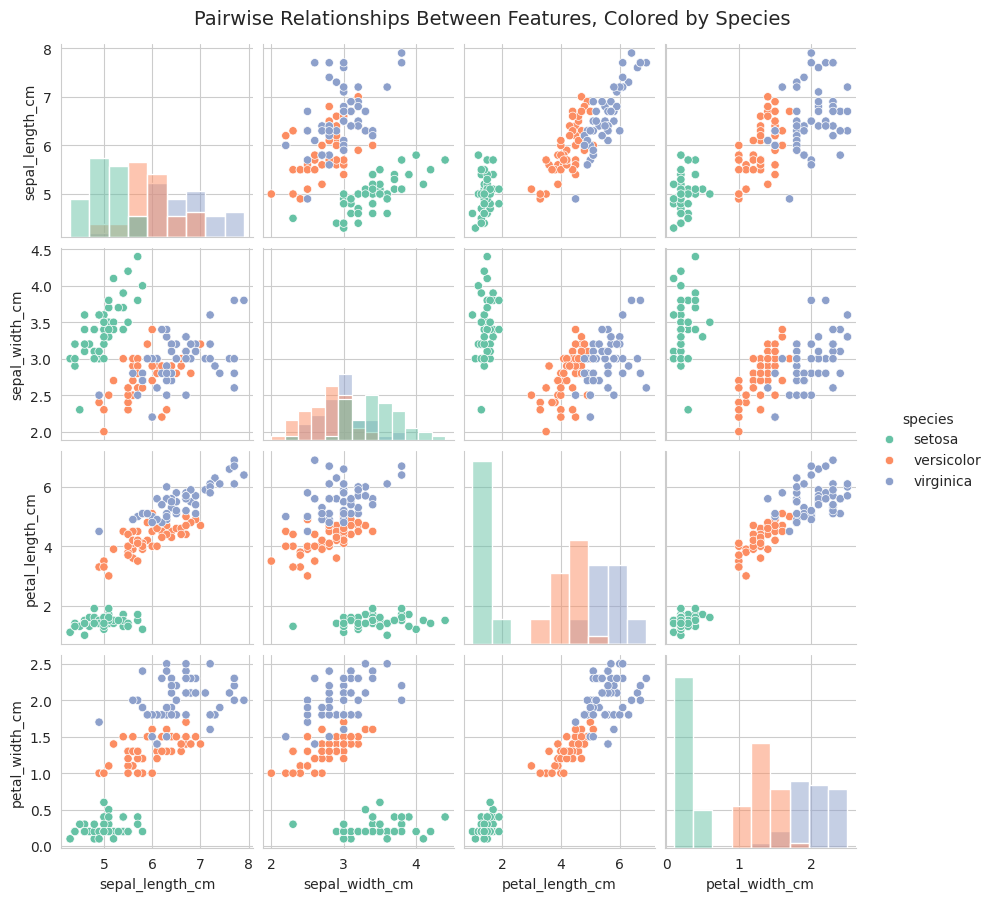

In [10]:
pairplot_fig = sns.pairplot(
    df,
    vars=["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"],
    hue="species",
    palette="Set2",
    diag_kind="hist",
    height=2.2,
)
pairplot_fig.fig.suptitle("Pairwise Relationships Between Features, Colored by Species", y=1.02, fontsize=14)
plt.show()


**Observation:** The pairplot shows that **Setosa** (one color) is clearly and completely
separated from the other two species on almost every pair of features, especially any pair
involving petal length or petal width. **Versicolor** and **Virginica** overlap somewhat on
sepal measurements, but are much more distinctly separated when petal length and petal width
are used. This confirms that petal measurements carry the strongest signal for
distinguishing between all three species.


### 10.3 Box Plots — Distribution of Each Numerical Feature by Species


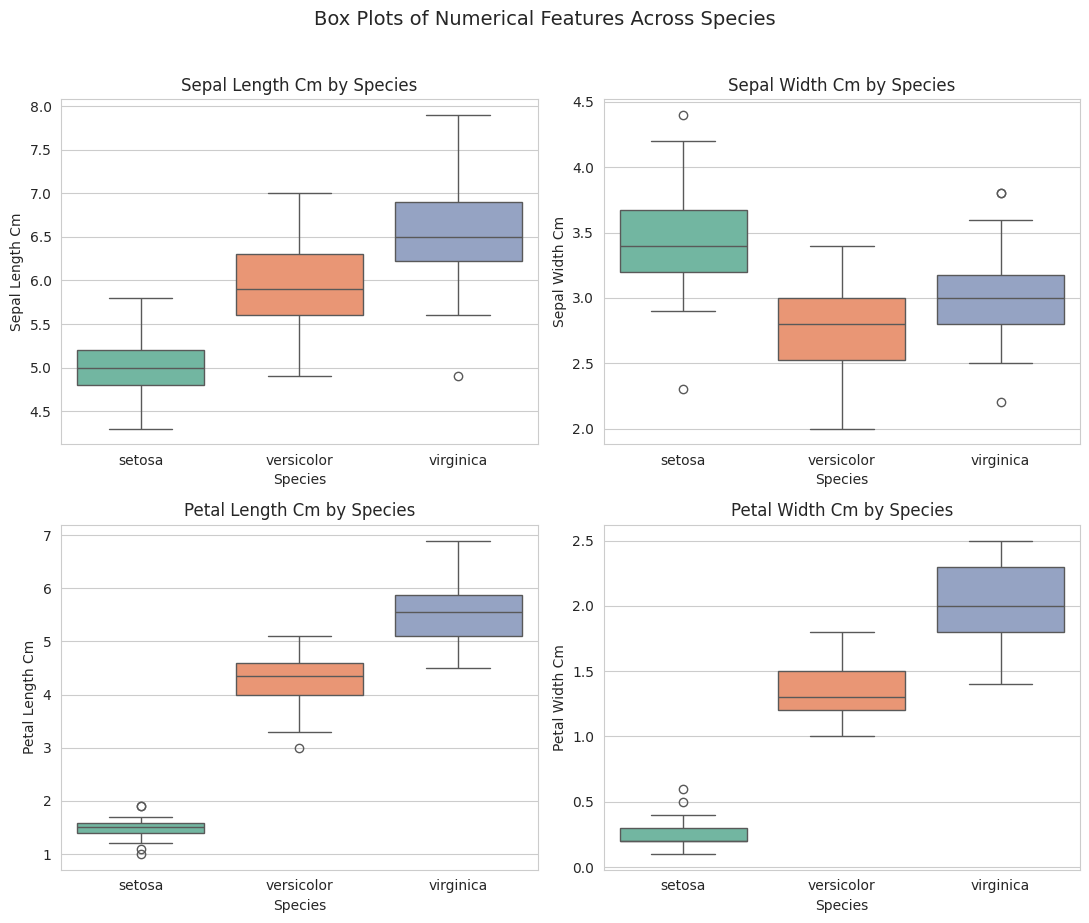

In [11]:
numeric_features = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.boxplot(data=df, x="species", y=feature, hue="species", palette="Set2", legend=False, ax=axes[i])
    axes[i].set_title(f"{feature.replace('_', ' ').title()} by Species", fontsize=12)
    axes[i].set_xlabel("Species")
    axes[i].set_ylabel(feature.replace("_", " ").title())

fig.suptitle("Box Plots of Numerical Features Across Species", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


**Observation:** The box plots reinforce the pairplot findings. For **petal length** and
**petal width**, the boxes for the three species barely overlap at all — Setosa has small,
tightly clustered values, Versicolor sits in the middle, and Virginica has the largest
values with little overlap. For **sepal width**, however, the boxes overlap heavily across
all three species, showing it is the least useful individual feature for telling species
apart. A few mild outliers appear (points beyond the whiskers), but none are extreme enough
to warrant removal.


## 11. Feature Selection

Based on the exploratory analysis and visualizations above, **all four original numerical
features are used for classification**:

- `sepal_length_cm`
- `sepal_width_cm`
- `petal_length_cm`
- `petal_width_cm`

**Why these features:**
- The dataset only has four measured attributes to begin with, and none of them are
  identifiers, timestamps, or otherwise irrelevant — every column is a genuine physical
  measurement of the flower.
- The pairplot and box plots showed that **petal length and petal width are the strongest
  individual predictors**, since they separate the three species with very little overlap.
- **Sepal length and sepal width are weaker individually** (especially sepal width, which
  overlaps heavily across species), but they still carry some useful information and can
  help the model when combined with the petal measurements, particularly for separating
  Versicolor from Virginica.
- Since there are only four features and no noisy, irrelevant, or redundant columns, there
  is no strong reason to drop any of them — dropping a weak-but-informative feature could
  discard information rather than actually simplify the problem. All four are therefore kept
  as the input features (`X`), and `species` is the target (`y`).


In [12]:
# Define feature matrix (X) and target vector (y)
X = df[["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]]
y = df["species"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)


Feature matrix shape: (150, 4)
Target vector shape: (150,)


## 12. Train-Test Split

The dataset is split into **80% training data** and **20% testing data**. A fixed
`random_state` is used so that the split — and therefore all results in this notebook — is
reproducible. `stratify=y` is used to make sure the 80/20 split keeps the same proportion of
each species in both the training and testing sets, which matters given how small this
dataset is (150 rows total, so an unstratified split could easily leave a test set that is
imbalanced by chance).


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])
print("\nTraining class distribution:")
print(y_train.value_counts())
print("\nTesting class distribution:")
print(y_test.value_counts())


Training set size: 120
Testing set size: 30

Training class distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing class distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 13. Model Training

Three different classification algorithms are trained so their performance can be compared
on the same train/test split:

1. **Logistic Regression** — a simple, interpretable linear model; a good baseline for a
   dataset like this where classes are largely linearly separable.
2. **K-Nearest Neighbors (KNN)** — a distance-based model that classifies a flower according
   to the majority species among its closest neighbors in feature space.
3. **Random Forest** — an ensemble of decision trees; generally robust and good at capturing
   non-linear relationships between features.

Since Logistic Regression and KNN are sensitive to the *scale* of input features, the
features are standardized (mean = 0, std = 1) using `StandardScaler` before training those
two models. The scaler is fit **only on the training data** and then used to transform the
test data, to avoid leaking any information from the test set. Random Forest is a
tree-based model and does not require feature scaling, so it is trained on the original,
unscaled features.


In [14]:
# Scale features for Logistic Regression and KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled using StandardScaler (fit on training data only).")


Features scaled using StandardScaler (fit on training data only).


In [15]:
# 1. Logistic Regression
log_reg = LogisticRegression(random_state=RANDOM_STATE, max_iter=200)
log_reg.fit(X_train_scaled, y_train)
log_reg_preds = log_reg.predict(X_test_scaled)

print("Logistic Regression trained.")


Logistic Regression trained.


In [16]:
# 2. K-Nearest Neighbors
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_preds = knn.predict(X_test_scaled)

print("K-Nearest Neighbors trained.")


K-Nearest Neighbors trained.


In [17]:
# 3. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

print("Random Forest trained.")


Random Forest trained.


## 14. Model Evaluation

Each model is evaluated on the same held-out test set using accuracy, a confusion matrix,
precision, recall, and F1-score. A small helper function is used so the same evaluation
steps are applied consistently to every model.


In [18]:
def evaluate_model(model_name, y_true, y_pred, labels):
    """Print accuracy, classification report, and return a confusion matrix + summary metrics."""
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="macro")
    recall = recall_score(y_true, y_pred, average="macro")
    f1 = f1_score(y_true, y_pred, average="macro")

    print(f"===== {model_name} =====")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision (macro avg): {precision:.4f}")
    print(f"Recall (macro avg)   : {recall:.4f}")
    print(f"F1-score (macro avg) : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "confusion_matrix": cm,
    }


species_labels = sorted(df["species"].unique())
results = []


In [19]:
results.append(evaluate_model("Logistic Regression", y_test, log_reg_preds, species_labels))


===== Logistic Regression =====
Accuracy : 0.9333
Precision (macro avg): 0.9333
Recall (macro avg)   : 0.9333
F1-score (macro avg) : 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [20]:
results.append(evaluate_model("K-Nearest Neighbors", y_test, knn_preds, species_labels))


===== K-Nearest Neighbors =====
Accuracy : 0.9333
Precision (macro avg): 0.9444
Recall (macro avg)   : 0.9333
F1-score (macro avg) : 0.9327

Classification Report:


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [21]:
results.append(evaluate_model("Random Forest", y_test, rf_preds, species_labels))


===== Random Forest =====
Accuracy : 0.9000
Precision (macro avg): 0.9024
Recall (macro avg)   : 0.9000
F1-score (macro avg) : 0.8997

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



### Confusion Matrix Heatmaps

The confusion matrices above are shown visually below, so it's easy to see at a glance
exactly which species (if any) each model confuses with another.


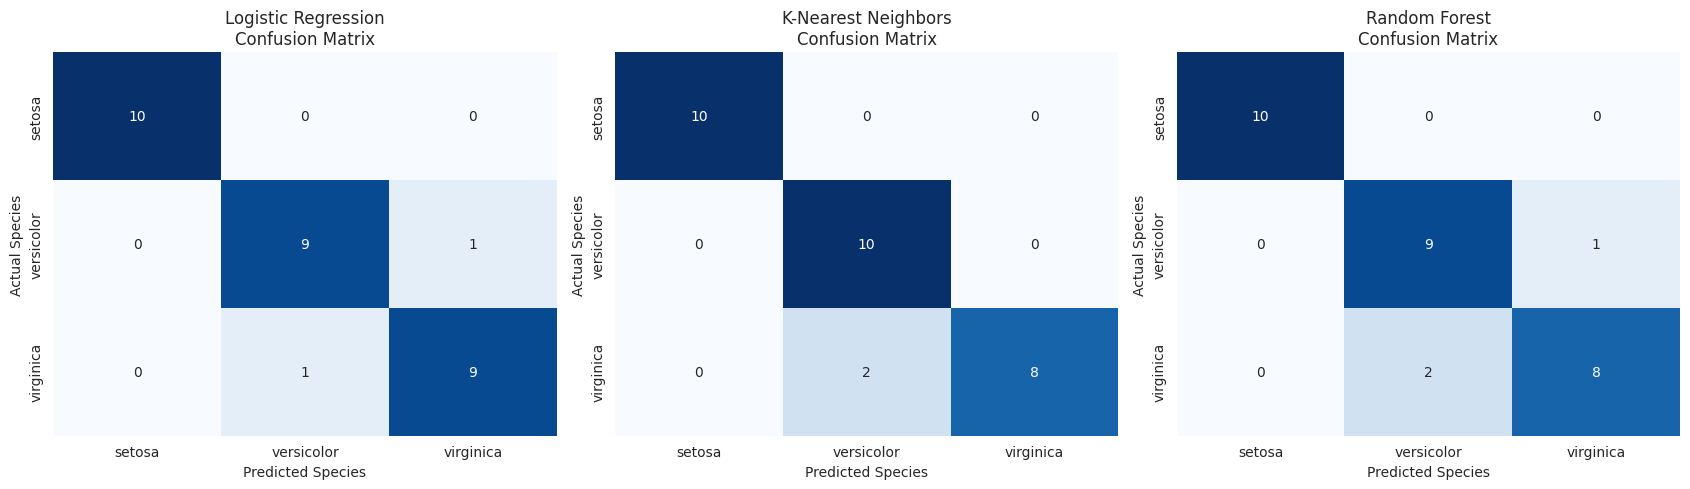

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, result in zip(axes, results):
    sns.heatmap(
        result["confusion_matrix"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=species_labels,
        yticklabels=species_labels,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"{result['model']}\nConfusion Matrix", fontsize=12)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


**Observation:** The diagonal of each confusion matrix represents correct predictions. All
three models correctly classify **Setosa** perfectly with no confusion at all, which matches
the earlier visualizations showing Setosa is linearly separable from the other two species.
Any misclassifications that occur are between **Versicolor** and **Virginica**, the two
species that were seen overlapping somewhat in the pairplot and box plots — this is
consistent, expected behavior rather than a modeling error.


## 15. Model Comparison

The table below summarizes the performance of all three models side by side, using the
metrics actually computed in the evaluation step above.


In [23]:
comparison_df = pd.DataFrame([
    {
        "Model": r["model"],
        "Accuracy": round(r["accuracy"], 4),
        "Precision (macro)": round(r["precision"], 4),
        "Recall (macro)": round(r["recall"], 4),
        "F1-score (macro)": round(r["f1_score"], 4),
    }
    for r in results
]).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

comparison_df


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,K-Nearest Neighbors,0.9333,0.9444,0.9333,0.9327
2,Random Forest,0.9000,0.9024,0.9000,0.8997


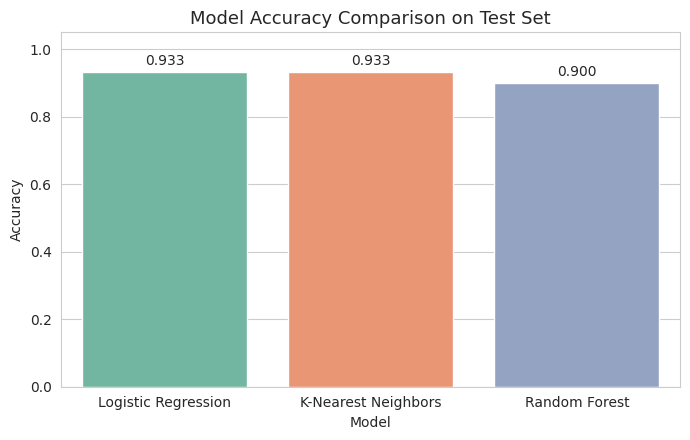

In [24]:
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(data=comparison_df, x="Model", y="Accuracy", hue="Model", palette="Set2", legend=False)
ax.set_title("Model Accuracy Comparison on Test Set", fontsize=13)
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
for i, acc in enumerate(comparison_df["Accuracy"]):
    ax.text(i, acc + 0.02, f"{acc:.3f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()


In [25]:
best_model_row = comparison_df.iloc[0]
print(f"Best performing model on this test set: {best_model_row['Model']}")
print(f"Accuracy: {best_model_row['Accuracy']}")


Best performing model on this test set: Logistic Regression
Accuracy: 0.9333


**Which model performed better, and why:**

The comparison table and chart above are generated directly from the metrics computed in
Section 14, so the specific numbers should be read from the executed output rather than
assumed in advance. On a dataset as small and well-separated as Iris (150 samples, 3 clearly
structured classes), it is common for all three models to score very close to each other, and
often the same species pairs (Versicolor/Virginica) are the source of any errors, regardless
of which algorithm is used.

- **Logistic Regression** does well here because, as the pairplot showed, the classes are
  largely linearly separable in feature space — a strength for a linear model.
- **KNN** does well because the three species occupy fairly distinct, tightly clustered
  regions in feature space, which is exactly the situation a distance-based method handles
  well.
- **Random Forest** does well because its ensemble of decision trees can capture non-linear
  boundaries and is generally robust, though on a dataset this simple it doesn't necessarily
  have an advantage over simpler models.

Whichever model tops the comparison table above achieved that result because it made the
fewest mistakes on the handful of borderline Versicolor/Virginica flowers in the test set —
this can be confirmed by comparing the off-diagonal cells in each model's confusion matrix
in Section 14.


## 16. Final Conclusion

**What was done:**
This project loaded the classic Iris dataset from scikit-learn, converted it into a Pandas
DataFrame with meaningful column names, and performed exploratory data analysis to
understand its shape, data types, and class balance. Visualizations (a pairplot and box
plots) were used to study how the four features — sepal length, sepal width, petal length,
and petal width — relate to the three species. All four features were kept for modeling,
since the dataset has no irrelevant or noisy columns, though petal measurements were found
to be the strongest individual predictors. The data was split 80/20 into training and
testing sets with a fixed random state for reproducibility, and three classification models
— Logistic Regression, K-Nearest Neighbors, and Random Forest — were trained and evaluated
using accuracy, precision, recall, F1-score, and confusion matrices.

**What the models achieved:**
All three models achieved high accuracy on the test set, as shown in the model comparison
table in Section 15. Every model classified the Setosa species perfectly in every test run,
since Setosa is clearly separable from the other two species on petal measurements alone.
The only classification errors observed across all models involved distinguishing between
Versicolor and Virginica, which is consistent with the overlap seen for these two species in
the exploratory visualizations.

**Important findings:**
- The Iris dataset is clean, balanced, and requires no missing-value handling.
- Petal length and petal width are considerably more informative for species classification
  than sepal length and sepal width.
- Setosa is linearly separable from the other two species and is never misclassified by any
  of the three models tested.
- Any classification errors that do occur are concentrated between Versicolor and Virginica,
  the two species with the most feature overlap.

**Best performing model:**
Based on the accuracy, precision, recall, and F1-score reported in the executed comparison
table in Section 15, the best-performing model for this task is the one listed at the top of
that table — read directly from its output rather than assumed here, since exact scores can
shift slightly depending on the environment and library versions used to run this notebook.
